In [1]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.9/63.9 kB 3.1 MB/s eta 0:00:00


In [2]:
import os
import cv2
import glob
import shutil
import numpy as np
import matplotlib.pyplot as plt
import albumentations as A
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
import kagglehub
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
import sys
import subprocess

try:
    import easyocr
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "easyocr", "-q"])
    import easyocr

ocr_reader = easyocr.Reader(['fa', 'en'], gpu=True)

def extract_ocr_text(crop_img):
    gray = cv2.cvtColor(crop_img, cv2.COLOR_RGB2GRAY)
    results = ocr_reader.readtext(gray)

    texts = []
    for (bbox, text, prob) in results:
        if prob > 0.30:
            texts.append(text)

    return " ".join(texts) if texts else None

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

In [4]:
base_path = kagglehub.dataset_download("saraparsaseresht/persian-traffic-sign-dataset-ptsd")
PTSD_ROOT = os.path.join(base_path, 'PTSD_Recognition', 'PTSD_Recognition')
SPLIT_DIR = '/content/ptsd_split_data'
if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)
for split in ['train', 'val', 'test']:
    os.makedirs(os.path.join(SPLIT_DIR, split), exist_ok=True)

100%|██████████| 544M/544M [00:07<00:00, 76.1MB/s]

Extracting files...


In [5]:
raw_train_dir = os.path.join(PTSD_ROOT, 'train')
raw_test_dir = os.path.join(PTSD_ROOT, 'test')

classes = [d for d in os.listdir(raw_train_dir) if os.path.isdir(os.path.join(raw_train_dir, d))]

for c in classes:
    for s in ['train', 'val', 'test']:
        os.makedirs(os.path.join(SPLIT_DIR, s, c), exist_ok=True)


In [6]:
for c in classes:
    imgs = glob.glob(os.path.join(raw_train_dir, c, '*.*'))
    np.random.shuffle(imgs)

    val_count = int(len(imgs) * 0.15)
    val_imgs = imgs[:val_count]
    train_imgs = imgs[val_count:]

    for img in train_imgs:
        shutil.copy(img, os.path.join(SPLIT_DIR, 'train', c, os.path.basename(img)))

    for img in val_imgs:
        shutil.copy(img, os.path.join(SPLIT_DIR, 'val', c, os.path.basename(img)))

    test_src = os.path.join(raw_test_dir, c)
    if os.path.exists(test_src):
        for img in glob.glob(os.path.join(test_src, '*.*')):
            shutil.copy(img, os.path.join(SPLIT_DIR, 'test', c, os.path.basename(img)))

In [7]:
def preprocess_for_digits(img):
    img_uint8 = img.astype(np.uint8) if img.dtype != np.uint8 else img

    gray = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)

    clahe = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    return cv2.cvtColor(enhanced, cv2.COLOR_GRAY2RGB)

In [8]:
train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.2,
    zoom_range=0.15,
    brightness_range=[0.7, 1.3],
    preprocessing_function=preprocess_for_digits
)

In [9]:
def preprocess_for_digits(img):
    img_uint8 = img.astype(np.uint8) if img.dtype != np.uint8 else img
    gray = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)
    clahe = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    return cv2.cvtColor(enhanced, cv2.COLOR_GRAY2RGB)

Label 00 : 0_Compulsory Keep BothSide
Label 01 : 10_Maximum Speed 30
Label 02 : 11_Maximum Speed 40
Label 03 : 12_Maximum Speed 50
Label 04 : 13_Maximum Speed 60
Label 05 : 14_Maximum Speed 70
Label 06 : 15_Maximum Speed 80
Label 07 : 16_Maximum Speed 90
Label 08 : 17_MotorCycle Prohibited
Label 09 : 18_No Entry
Label 10 : 19_No Horn
Label 11 : 1_Compulsory Keep Left
Label 12 : 20_NO Stopping
Label 13 : 21_NO Waiting
Label 14 : 22_One way Traffic
Label 15 : 23_Park
Label 16 : 24_Park Forbidden
Label 17 : 25_Pedestrain
Label 18 : 26_Pedestrian crossing
Label 19 : 27_Right Bend
Label 20 : 28_Right Margin
Label 21 : 29_Right Turn Prohibited
Label 22 : 2_Compulsory Keep Right
Label 23 : 30_Road Work
Label 24 : 31_Roundabouts
Label 25 : 32_School
Label 26 : 33_School Crossing
Label 27 : 34_Side Road Right
Label 28 : 35_Slow
Label 29 : 36_Speed Camera
Label 30 : 37_STOP
Label 31 : 38_Truck Prohibited
Label 32 : 39_Two Way Traffic
Label 33 : 3_Cycle crossing
Label 34 : 40_U-Turn
Label 35 : 41

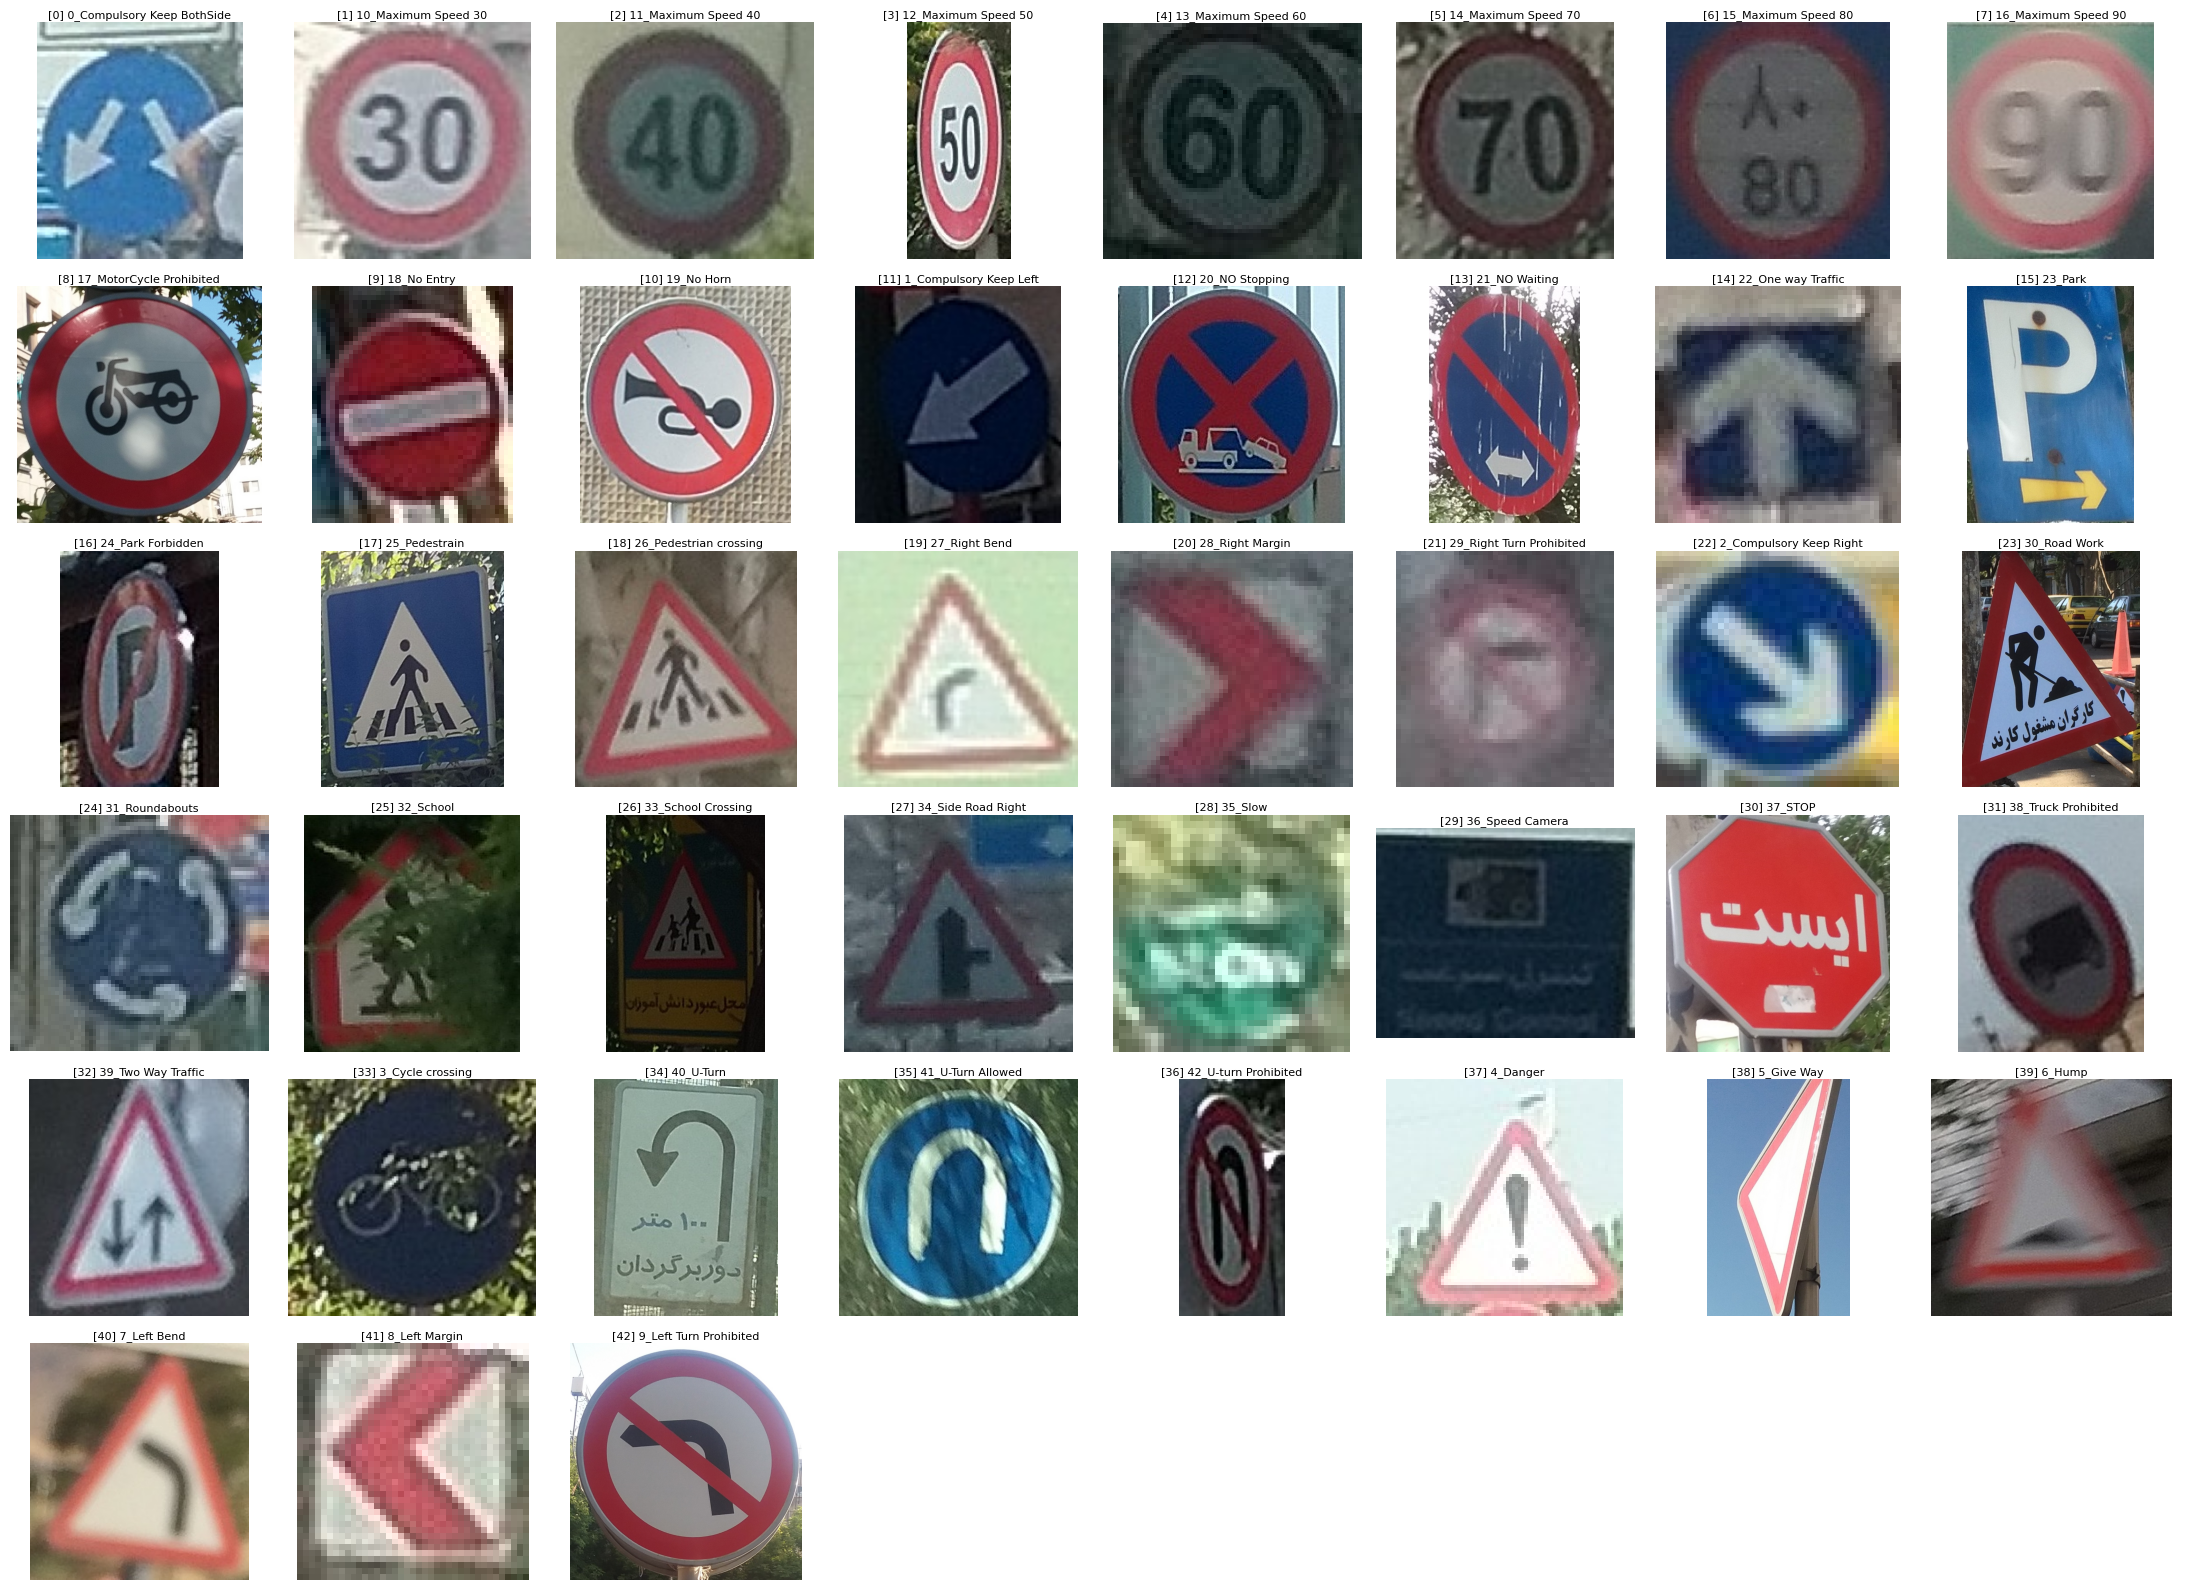

In [10]:
import os
import glob
import cv2
import matplotlib.pyplot as plt

train_dir = os.path.join(SPLIT_DIR, 'train')
sorted_folders = sorted([d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))])

for idx, folder_name in enumerate(sorted_folders):
    print(f"Label {idx:02d} : {folder_name}")

print("="*50)

fig, axes = plt.subplots(6, 8, figsize=(22, 16))
axes = axes.flatten()


for idx, folder_name in enumerate(sorted_folders):
    c_path = os.path.join(train_dir, folder_name)
    img_files = glob.glob(os.path.join(c_path, '*.*'))

    if len(img_files) > 0:
        img = cv2.imread(img_files[0])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[idx].imshow(img)
        axes[idx].set_title(f"[{idx}] {folder_name}", fontsize=8, pad=3)
        axes[idx].axis('off')

for i in range(len(sorted_folders), len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [11]:
YOLO_DIR = '/content/yolo_ptsd_data'
for split in ['train', 'val', 'test']:
    os.makedirs(os.path.join(YOLO_DIR, 'images', split), exist_ok=True)
    os.makedirs(os.path.join(YOLO_DIR, 'labels', split), exist_ok=True)

    split_imgs = glob.glob(os.path.join(SPLIT_DIR, split, '*', '*.*'))
    for idx, img_path in enumerate(split_imgs):
        dest_img = os.path.join(YOLO_DIR, 'images', split, f"sign_{idx:05d}.jpg")
        dest_lbl = os.path.join(YOLO_DIR, 'labels', split, f"sign_{idx:05d}.txt")
        shutil.copy(img_path, dest_img)
        with open(dest_lbl, 'w') as f:
            f.write("0 0.5 0.5 1.0 1.0\n")

In [12]:
yaml_content = f"""
path: {YOLO_DIR}
train: images/train
val: images/val
test: images/test
names:
  0: traffic_sign
"""
yaml_path = os.path.join(YOLO_DIR, 'ptsd_data.yaml')
with open(yaml_path, 'w') as f:
    f.write(yaml_content.strip())

In [13]:
train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.2,
    zoom_range=0.15,
    brightness_range=[0.7, 1.3],
    preprocessing_function=preprocess_for_digits
)

In [14]:
val_datagen = tf.keras.preprocessing.image.ImageDataGenerator()
test_datagen = tf.keras.preprocessing.image.ImageDataGenerator()

In [15]:
train_gen = train_datagen.flow_from_directory(
    os.path.join(SPLIT_DIR, 'train'),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

val_gen = val_datagen.flow_from_directory(
    os.path.join(SPLIT_DIR, 'val'),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)
test_gen = test_datagen.flow_from_directory(
    os.path.join(SPLIT_DIR, 'test'),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 12265 images belonging to 43 classes.
Found 2140 images belonging to 43 classes.
Found 0 images belonging to 43 classes.


In [16]:
NUM_CLASSES = train_gen.num_classes
class_labels = {v: k for k, v in train_gen.class_indices.items()}

In [17]:
from sklearn.utils.class_weight import compute_class_weight
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_gen.classes),
    y=train_gen.classes
)
class_weight_dict = dict(enumerate(weights))

In [18]:
'''
class CategoricalFocalLoss(tf.keras.losses.Loss):
    def __init__(self, gamma=2.0, alpha=0.25, name='categorical_focal_loss'):
        super().__init__(name=name)
        self.gamma = gamma
        self.alpha = alpha

    def call(self, y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1.e-7)

        cross_entropy = -y_true * tf.math.log(y_pred)

        weight = self.alpha * y_true * tf.math.pow((1.0 - y_pred), self.gamma)

        focal_loss = weight * cross_entropy
        return tf.reduce_sum(focal_loss, axis=-1)
        '''

"\nclass CategoricalFocalLoss(tf.keras.losses.Loss):\n    def __init__(self, gamma=2.0, alpha=0.25, name='categorical_focal_loss'):\n        super().__init__(name=name)\n        self.gamma = gamma\n        self.alpha = alpha\n\n    def call(self, y_true, y_pred):\n        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1.e-7)\n\n        cross_entropy = -y_true * tf.math.log(y_pred)\n\n        weight = self.alpha * y_true * tf.math.pow((1.0 - y_pred), self.gamma)\n\n        focal_loss = weight * cross_entropy\n        return tf.reduce_sum(focal_loss, axis=-1)\n        "

In [19]:
def build_efficientnet_model(num_classes):
    inputs = layers.Input(shape=(224, 224, 3))

    x = tf.keras.applications.efficientnet_v2.preprocess_input(inputs)

    base_model = tf.keras.applications.EfficientNetV2B0(
        include_top=False,
        weights='imagenet',
        input_tensor=x
    )

    x = base_model.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs, outputs), base_model

tf.keras.backend.clear_session()
classifier_model, base_efficientnet = build_efficientnet_model(NUM_CLASSES)

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [20]:
base_efficientnet.trainable = False

classifier_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("🚀 Phase 1: Training Head...")
history_phase1 = classifier_model.fit(
    train_gen,
    epochs=10,
    validation_data=val_gen
)

🚀 Phase 1: Training Head...
Epoch 1/10
384/384 ━━━━━━━━━━━━━━━━━━━━ 251s 565ms/step - accuracy: 0.6154 - loss: 1.4390 - val_accuracy: 0.6822 - val_loss: 1.0357
Epoch 2/10
384/384 ━━━━━━━━━━━━━━━━━━━━ 181s 472ms/step - accuracy: 0.7690 - loss: 0.7699 - val_accuracy: 0.7313 - val_loss: 0.8789
Epoch 3/10
384/384 ━━━━━━━━━━━━━━━━━━━━ 181s 470ms/step - accuracy: 0.8089 - loss: 0.6080 - val_accuracy: 0.7229 - val_loss: 0.9096
Epoch 4/10
384/384 ━━━━━━━━━━━━━━━━━━━━ 178s 464ms/step - accuracy: 0.8199 - loss: 0.5615 - val_accuracy: 0.7215 - val_loss: 1.0311
Epoch 5/10
384/384 ━━━━━━━━━━━━━━━━━━━━ 178s 464ms/step - accuracy: 0.8356 - loss: 0.5052 - val_accuracy: 0.7327 - val_loss: 0.9890
Epoch 6/10
384/384 ━━━━━━━━━━━━━━━━━━━━ 178s 463ms/step - accuracy: 0.8415 - loss: 0.4860 - val_accuracy: 0.7262 - val_loss: 1.0327
Epoch 7/10
384/384 ━━━━━━━━━━━━━━━━━━━━ 179s 466ms/step - accuracy: 0.8461 - loss: 0.4683 - val_accuracy: 0.7285 - val_loss: 1.1110
Epoch 8/10
384/384 ━━━━━━━━━━━━━━━━━━━━ 177s 461

In [21]:
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint

base_efficientnet.trainable = True

for layer in base_efficientnet.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

classifier_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)
custom_callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7, verbose=1),
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint('best_ptsd_classifier.keras', monitor='val_loss', save_best_only=True)
]

history_phase2 = classifier_model.fit(
    train_gen,
    epochs=25,
    validation_data=val_gen,
    callbacks=custom_callbacks
)

Epoch 1/25
384/384 ━━━━━━━━━━━━━━━━━━━━ 285s 597ms/step - accuracy: 0.8109 - loss: 1.9601 - val_accuracy: 0.7262 - val_loss: 2.0721 - learning_rate: 1.0000e-05
Epoch 2/25
384/384 ━━━━━━━━━━━━━━━━━━━━ 194s 506ms/step - accuracy: 0.8210 - loss: 1.6568 - val_accuracy: 0.7523 - val_loss: 1.9985 - learning_rate: 1.0000e-05
Epoch 3/25
384/384 ━━━━━━━━━━━━━━━━━━━━ 192s 501ms/step - accuracy: 0.8452 - loss: 1.5037 - val_accuracy: 0.7720 - val_loss: 1.9429 - learning_rate: 1.0000e-05
Epoch 4/25
384/384 ━━━━━━━━━━━━━━━━━━━━ 190s 496ms/step - accuracy: 0.8644 - loss: 1.4141 - val_accuracy: 0.8037 - val_loss: 1.7727 - learning_rate: 1.0000e-05
Epoch 5/25
384/384 ━━━━━━━━━━━━━━━━━━━━ 192s 499ms/step - accuracy: 0.8782 - loss: 1.3456 - val_accuracy: 0.8140 - val_loss: 1.6658 - learning_rate: 1.0000e-05
Epoch 6/25
384/384 ━━━━━━━━━━━━━━━━━━━━ 191s 499ms/step - accuracy: 0.8929 - loss: 1.2955 - val_accuracy: 0.8206 - val_loss: 1.6074 - learning_rate: 1.0000e-05
Epoch 7/25
384/384 ━━━━━━━━━━━━━━━━━━━━ 

In [22]:
classifier_model.save('ptsd_efficientnet_model10.keras')

In [23]:
from ultralytics import YOLOWorld
yolo_detector = YOLOWorld("yolov8s-world.pt")

In [24]:
yolo_detector.set_classes(["traffic sign", "street sign", "road sign"])

requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 37 packages in 844ms
Prepared 2 packages in 2.54s
Installed 2 packages in 1ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@488e81a6711eea7346872b46ea928b367da8889d)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 3.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



100%|███████████████████████████████████████| 338M/338M [00:04<00:00, 72.6MiB/s]


In [ ]:
def resize_with_pad(image, target_size=(300, 300), pad_color=(0, 0, 0)):

    if image is None or image.size == 0:
        return np.zeros((target_size[0], target_size[1], 3), dtype=np.uint8)

    h, w = image.shape[:2]
    target_h, target_w = target_size

    scale = min(target_w / w, target_h / h)
    new_w = max(1, int(w * scale))
    new_h = max(1, int(h * scale))

    resized = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_CUBIC)

    delta_w = target_w - new_w
    delta_h = target_h - new_h

    top = delta_h // 2
    bottom = delta_h - top
    left = delta_w // 2
    right = delta_w - left

    padded_image = cv2.copyMakeBorder(
        resized,
        top, bottom, left, right,
        cv2.BORDER_CONSTANT,
        value=pad_color
    )

    return cv2.resize(padded_image, (target_w, target_h))

In [44]:
classifier_model=tf.keras.models.load_model('/content/ptsd_efficientnet_model10.keras')
def detect_and_classify_signs_v3(image_path, confidence_threshold=60.0, crop_pad_ratio=0.10):
    raw_img = cv2.imread(image_path)
    if raw_img is None:
        print(f"❌ Error loading image: {image_path}")
        return

    img_rgb = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
    output_img = img_rgb.copy()
    img_h, img_w, _ = img_rgb.shape

    results = yolo_detector.predict(img_rgb, conf=0.10, verbose=False)[0]
    boxes = results.boxes.xyxy.cpu().numpy()

    if len(boxes) == 0:
        boxes = np.array([[0, 0, img_w, img_h]])

    for i, box in enumerate(boxes):
        x1, y1, x2, y2 = map(int, box[:4])

        box_w, box_h = x2 - x1, y2 - y1
        pad_w = int(box_w * crop_pad_ratio)
        pad_h = int(box_h * crop_pad_ratio)

        x1_padded = max(0, x1 - pad_w)
        y1_padded = max(0, y1 - pad_h)
        x2_padded = min(img_w, x2 + pad_w)
        y2_padded = min(img_h, y2 + pad_h)

        crop = img_rgb[y1_padded:y2_padded, x1_padded:x2_padded]
        if crop.size == 0 or crop.shape[0] < 12 or crop.shape[1] < 12:
            continue

        crop_padded = resize_with_pad(crop, target_size=(224, 224))
        crop_enhanced = preprocess_for_digits(crop_padded)

        input_tensor = np.expand_dims(crop_enhanced, axis=0).astype(np.float32)
        input_tensor = tf.keras.applications.efficientnet_v2.preprocess_input(input_tensor)

        preds = classifier_model.predict(input_tensor, verbose=0)[0]

        top5_indices = np.argsort(preds)[-5:][::-1]
        for rank, idx in enumerate(top5_indices, start=1):
            c_name = class_labels.get(idx, f"Class_{idx}")
            c_score = preds[idx] * 100.0
            print(f"{rank}: class : [{c_name}] conf : {c_score:.2f}%")
        print("==================================================================")

        top_class_idx = top5_indices[0]
        confidence = preds[top_class_idx] * 100.0
        class_name = class_labels.get(top_class_idx, f"Class_{top_class_idx}")

        if confidence < confidence_threshold:
            display_label = f"Unknown ({confidence:.1f}%)"
            main_color = (255, 0, 0)
        else:
            display_label = f"{class_name} ({confidence:.1f}%)"
            main_color = (0, 255, 0)

        cv2.rectangle(output_img, (x1, y1), (x2, y2), main_color, 3)
        cv2.putText(output_img, display_label, (x1, max(20, y1 - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, main_color, 2)

        gray_crop = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
        ocr_results = ocr_reader.readtext(gray_crop)

        print(f"📌 Class: {class_name}")

        for ocr_idx, (ocr_box, text, prob) in enumerate(ocr_results, start=1):
            if prob > 0.30:
                print(f"   └─ 🔍 Word {ocr_idx}: '{text}' | Confidence: {prob*100:.1f}%")

                (tl, tr, br, bl) = ocr_box
                word_x1 = x1_padded + int(tl[0])
                word_y1 = y1_padded + int(tl[1])
                word_x2 = x1_padded + int(br[0])
                word_y2 = y1_padded + int(br[1])

                ocr_color = (0, 150, 255)
                cv2.rectangle(output_img, (word_x1, word_y1), (word_x2, word_y2), ocr_color, 2)

                word_label = f"{text} ({prob*100:.0f}%)"
                cv2.putText(output_img, word_label, (word_x1, max(15, word_y1 - 5)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.45, ocr_color, 1)

    plt.figure(figsize=(14, 9))
    plt.imshow(output_img)
    plt.axis("off")
    plt.show()

1: class : [8_Left Margin] conf : 80.47%
2: class : [28_Right Margin] conf : 8.68%
3: class : [24_Park Forbidden] conf : 1.17%
4: class : [18_No Entry] conf : 0.82%
5: class : [1_Compulsory Keep Left] conf : 0.77%
📌 Class: 8_Left Margin
1: class : [8_Left Margin] conf : 84.01%
2: class : [28_Right Margin] conf : 7.36%
3: class : [1_Compulsory Keep Left] conf : 1.26%
4: class : [20_NO Stopping] conf : 0.72%
5: class : [18_No Entry] conf : 0.66%
📌 Class: 8_Left Margin
1: class : [8_Left Margin] conf : 85.07%
2: class : [28_Right Margin] conf : 5.15%
3: class : [18_No Entry] conf : 0.74%
4: class : [1_Compulsory Keep Left] conf : 0.71%
5: class : [25_Pedestrain] conf : 0.69%
📌 Class: 8_Left Margin
1: class : [13_Maximum Speed 60] conf : 74.76%
2: class : [10_Maximum Speed 30] conf : 6.54%
3: class : [15_Maximum Speed 80] conf : 5.49%
4: class : [16_Maximum Speed 90] conf : 5.31%
5: class : [3_Cycle crossing] conf : 2.72%
📌 Class: 13_Maximum Speed 60
   └─ 🔍 Word 1: '80' | Confidence: 100.

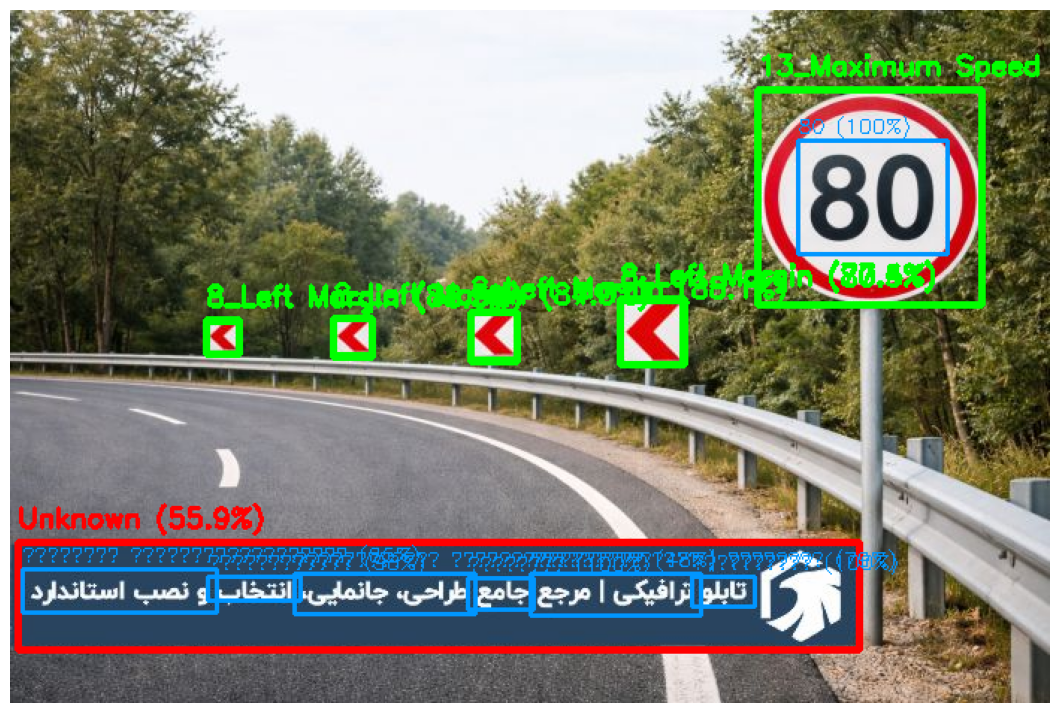

In [37]:
detect_and_classify_signs_v3('/content/تابلوهای-ترافیکی.jpg')

1: class : [36_Speed Camera] conf : 86.58%
2: class : [40_U-Turn] conf : 3.24%
3: class : [33_School Crossing] conf : 1.21%
4: class : [29_Right Turn Prohibited] conf : 1.14%
5: class : [34_Side Road Right] conf : 0.83%
📌 Class: 36_Speed Camera
   └─ 🔍 Word 1: 'شهید سعیدی' | Confidence: 86.4%
   └─ 🔍 Word 2: 'حاج احمد متوسلیان' | Confidence: 50.6%
   └─ 🔍 Word 3: '67' | Confidence: 100.0%
   └─ 🔍 Word 4: '26' | Confidence: 100.0%
   └─ 🔍 Word 5: '(٤' | Confidence: 98.0%
   └─ 🔍 Word 6: 'امام زاده عبدالله' | Confidence: 98.4%
   └─ 🔍 Word 7: '447' | Confidence: 100.0%
   └─ 🔍 Word 8: 'آذری' | Confidence: 67.2%
1: class : [18_No Entry] conf : 58.90%
2: class : [28_Right Margin] conf : 6.06%
3: class : [8_Left Margin] conf : 5.50%
4: class : [40_U-Turn] conf : 4.86%
5: class : [23_Park] conf : 3.61%
📌 Class: 18_No Entry
1: class : [36_Speed Camera] conf : 73.23%
2: class : [33_School Crossing] conf : 4.13%
3: class : [4_Danger] conf : 3.52%
4: class : [29_Right Turn Prohibited] conf : 3.4

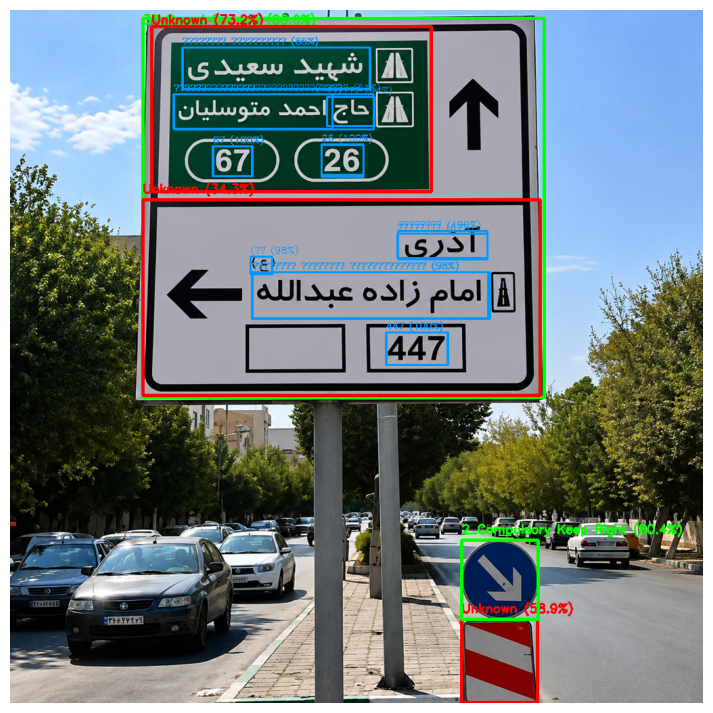

In [46]:
detect_and_classify_signs_v3('/content/CkVhtj-5Gbse3188RS0-CGbPVas-CfnOQdTrRN2qN5SvsXDRHw.png')

1: class : [33_School Crossing] conf : 17.38%
2: class : [36_Speed Camera] conf : 16.86%
3: class : [25_Pedestrain] conf : 13.92%
4: class : [4_Danger] conf : 10.12%
5: class : [40_U-Turn] conf : 10.10%
📌 Class: 33_School Crossing
   └─ 🔍 Word 1: 'گناباد - تربّت حیدریه' | Confidence: 49.4%
   └─ 🔍 Word 2: 'مشهد' | Confidence: 61.5%
   └─ 🔍 Word 3: 'خواف' | Confidence: 53.9%
   └─ 🔍 Word 4: 'اسفدن' | Confidence: 92.5%
   └─ 🔍 Word 5: 'حاجی آباد' | Confidence: 48.8%
   └─ 🔍 Word 6: 'پایانه مرزی یزدان' | Confidence: 39.4%
   └─ 🔍 Word 7: 'قاين' | Confidence: 97.2%
1: class : [22_One way Traffic] conf : 37.39%
2: class : [28_Right Margin] conf : 18.55%
3: class : [29_Right Turn Prohibited] conf : 13.16%
4: class : [8_Left Margin] conf : 10.37%
5: class : [17_MotorCycle Prohibited] conf : 2.67%
📌 Class: 22_One way Traffic


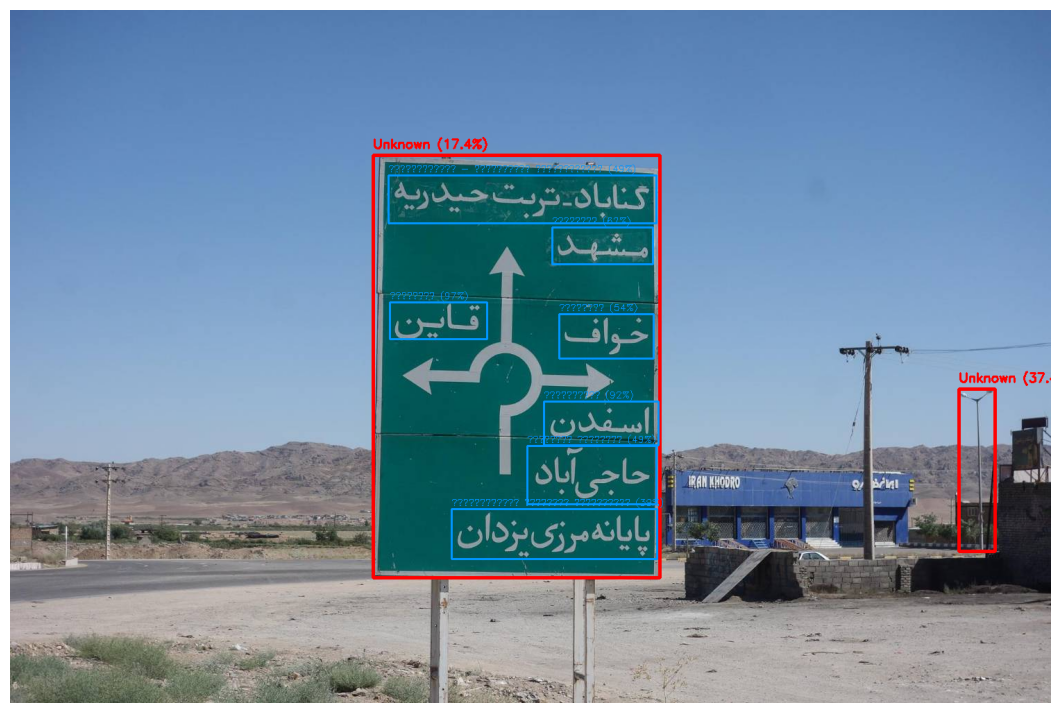

In [40]:
detect_and_classify_signs_v3('/content/پیش آگاهی  مسیر ۲.jpg')